### **Tahap 0: Persiapan Library & Pemanggilan Dataset dari GitHub**

In [2]:
# === SEL 1: IMPORT LIBRARY & LOAD DATASET DARI GITHUB ===

import pandas as pd
import numpy as np
import missingno as msno
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler, LabelEncoder

# 1. Tulis base_url SATU KALI saja dan berhenti di nama folder (diakhiri tanda /)
base_url = 'https://raw.githubusercontent.com/jusrilhamzah/tugas1-penambangan-data-preprocessing/refs/heads/main/Dataset_Kafe_Kopi_Nusantara/'

# 2. Gabungkan base_url dengan masing-masing nama file CSV
df_trx = pd.read_csv(base_url + 'dataset_awal.csv')
df_pel = pd.read_csv(base_url + 'data_pelanggan.csv')
df_jan = pd.read_csv(base_url + 'transaksi_januari.csv')
df_feb = pd.read_csv(base_url + 'transaksi_februari.csv')
df_harian = pd.read_csv(base_url + 'transaksi_harian.csv')
df_mingguan = pd.read_csv(base_url + 'transaksi_mingguan.csv')
df_detik = pd.read_csv(base_url + 'pelayanan_detik.csv')
df_menit = pd.read_csv(base_url + 'pelayanan_menit.csv')

# 3. Inspeksi awal dataset utama
print("Ukuran dataset_awal:", df_trx.shape)
print(df_trx.info())
df_trx.head()

Ukuran dataset_awal: (248, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 248 entries, 0 to 247
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_transaksi          248 non-null    object 
 1   id_pelanggan          240 non-null    object 
 2   tanggal_transaksi     242 non-null    object 
 3   outlet                238 non-null    object 
 4   jenis_kelamin         238 non-null    object 
 5   usia                  233 non-null    object 
 6   kategori_menu         240 non-null    object 
 7   jumlah_item           237 non-null    object 
 8   total_harga           235 non-null    object 
 9   metode_pembayaran     239 non-null    object 
 10  durasi_layanan_menit  235 non-null    float64
 11  rating_kepuasan       233 non-null    float64
dtypes: float64(2), object(10)
memory usage: 23.4+ KB
None


,id_transaksi,id_pelanggan,tanggal_transaksi,outlet,jenis_kelamin,usia,kategori_menu,jumlah_item,total_harga,metode_pembayaran,durasi_layanan_menit,rating_kepuasan
0,TRX-0001,CUST-092,2026-01-01,Surabaya Pusat,Perempuan,33,Camilan,3,NaN,QRIS,14.6,4.0
1,TRX-0002,CUST-078,2026-01-01,Surabaya Pusat,Perempuan,18,Makanan Berat,2,63000,QRIS,8.4,NaN
2,TRX-0003,CUST-050,2026-01-01,Surabaya Barat,Perempuan,33,Camilan,1,14000,Qris,8.3,4.0
3,TRX-0004,CUST-019,02-01-2026,Surabaya Barat,Perempuan,36,Kopi,2,51000,E-Wallet,13.4,4.0
4,TRX-0005,CUST-079,02/01/2026,Surabaya Pusat,Laki-laki,18,Kopi,2,47000,E-Wallet,6.5,5.0


### **Tahap 1: Data Cleansing & Konsistensi Data**

**1.1 Deteksi & Penghapusan Data Duplikat**

In [ ]:
# === SEL 2: PENANGANAN DATA DUPLIKAT ===
print("Jumlah duplikat dataset_awal:", df_trx.duplicated().sum())
print("Jumlah duplikat data_pelanggan:", df_pel.duplicated().sum())
print("Jumlah duplikat pelayanan_detik:", df_detik.duplicated().sum())
print("Jumlah duplikat pelayanan_menit:", df_menit.duplicated().sum())

# Hapus baris duplikat pada seluruh dataset
df_trx = df_trx.drop_duplicates().reset_index(drop=True)
df_pel = df_pel.drop_duplicates().reset_index(drop=True)
df_jan = df_jan.drop_duplicates().reset_index(drop=True)
df_feb = df_feb.drop_duplicates().reset_index(drop=True)
df_harian = df_harian.drop_duplicates().reset_index(drop=True)
df_detik = df_detik.drop_duplicates().reset_index(drop=True)
df_menit = df_menit.drop_duplicates().reset_index(drop=True)

print("Ukuran dataset_awal setelah hapus duplikat:", df_trx.shape)

Jumlah duplikat dataset_awal: 8
Jumlah duplikat data_pelanggan: 5
Jumlah duplikat pelayanan_detik: 4
Jumlah duplikat pelayanan_menit: 4
Ukuran dataset_awal setelah hapus duplikat: (240, 12)


**1.2 Pembersihan Teks, Spasi Berlebih, Kapitalisasi, & Typo Kategori**

In [ ]:
# === SEL 3: PEMBERSIHAN TEKS & PENYERAGAMAN KATEGORI ===
# Cek jumlah kategori sebelum pembersihan (sesuai acuan file referensi)
print("=== SEBELUM CLEANING ===")
print(df_trx.groupby("outlet").count()["id_transaksi"])
print(df_trx.groupby("kategori_menu").count()["id_transaksi"])

kolom_teks = ['outlet', 'jenis_kelamin', 'kategori_menu', 'metode_pembayaran']

# 1. Hilangkan spasi berlebih (depan, belakang, dan ganda di tengah)
df_trx[kolom_teks] = df_trx[kolom_teks].apply(lambda x: x.str.strip() if x.dtype == "object" else x)
df_trx[kolom_teks] = df_trx[kolom_teks].apply(lambda x: x.str.replace(r'\s+', ' ', regex=True) if x.dtype == "object" else x)

# 2. Seragamkan huruf kapital (.upper())
for col in kolom_teks:
    df_trx[col] = df_trx[col].apply(lambda x: x.upper() if isinstance(x, str) else x)

# 3. Replace variasi penulisan, singkatan, dan typo
df_trx['outlet'] = df_trx['outlet'].replace({
    'SBY PUSAT': 'SURABAYA PUSAT',
    'SBY BARAT': 'SURABAYA BARAT',
    'SBY TIMUR': 'SURABAYA TIMUR'
})

df_trx['jenis_kelamin'] = df_trx['jenis_kelamin'].replace({
    'L': 'LAKI-LAKI', 'PRIA': 'LAKI-LAKI',
    'P': 'PEREMPUAN', 'WANITA': 'PEREMPUAN'
})

df_trx['kategori_menu'] = df_trx['kategori_menu'].replace({
    'SNACK': 'CAMILAN', 'CEMILAN': 'CAMILAN',
    'MKN BERAT': 'MAKANAN BERAT',
    'NON KOPI': 'NON-KOPI', 'NONKOPI': 'NON-KOPI'
})

df_trx['metode_pembayaran'] = df_trx['metode_pembayaran'].replace({
    'QR CODE': 'QRIS',
    'CASH': 'TUNAI',
    'DEBIT': 'KARTU DEBIT',
    'EWALLET': 'E-WALLET', 'E WALLET': 'E-WALLET'
})

# Cek jumlah kategori sesudah pembersihan
print("\n=== SESUDAH CLEANING ===")
print(df_trx.groupby("outlet").count()["id_transaksi"])
print(df_trx.groupby("kategori_menu").count()["id_transaksi"])
print(df_trx.groupby("jenis_kelamin").count()["id_transaksi"])
print(df_trx.groupby("metode_pembayaran").count()["id_transaksi"])

=== SEBELUM CLEANING ===
outlet
 Surabaya Pusat     5
SBY Pusat           5
SBY Timur           6
SURABAYA BARAT      1
Sby Barat           2
Surabaya  Barat     6
Surabaya  Pusat     7
Surabaya Barat     43
Surabaya Pusat     78
Surabaya Timur     56
Surabaya Timur      2
surabaya pusat     14
surabaya timur      6
Name: id_transaksi, dtype: int64
kategori_menu
Camilan          36
Cemilan           1
KOPI              9
Kopi             73
Kopi              5
Makanan Berat    39
Makanan berat     3
Mkn Berat         5
Non Kopi          3
Non-Kopi         44
NonKopi           1
Snack             3
camilan           2
kopi              2
makanan berat     1
non-kopi          5
Name: id_transaksi, dtype: int64

=== SESUDAH CLEANING ===
outlet
SURABAYA BARAT     52
SURABAYA PUSAT    109
SURABAYA TIMUR     70
Name: id_transaksi, dtype: int64
kategori_menu
CAMILAN          42
KOPI             89
MAKANAN BERAT    48
NON-KOPI         53
Name: id_transaksi, dtype: int64
jenis_kelamin
LAKI-LAKI

**1.3 Penyeragaman Format Tanggal, Teks Angka, & Mata Uang**

In [ ]:
# === SEL 4: KONVERSI FORMAT TANGGAL & TIPE DATA NUMERIK ===
# 1. Seragamkan format tanggal (YYYY-MM-DD, DD/MM/YYYY, '5 Jan 2026', dll.)
df_trx['tanggal_transaksi'] = pd.to_datetime(
    df_trx['tanggal_transaksi'], format='mixed', dayfirst=True, errors='coerce'
)

# 2. Bersihkan teks pada kolom 'usia' ('30 th', 'dua puluh lima') -> numerik
df_trx['usia'] = df_trx['usia'].replace({'30 th': '30', 'dua puluh lima': '25'})
df_trx['usia'] = pd.to_numeric(df_trx['usia'], errors='coerce')

# 3. Bersihkan teks angka pada kolom 'jumlah_item' ('dua', 'tiga', 'lima') -> numerik
df_trx['jumlah_item'] = df_trx['jumlah_item'].replace({'dua': '2', 'tiga': '3', 'lima': '5'})
df_trx['jumlah_item'] = pd.to_numeric(df_trx['jumlah_item'], errors='coerce')

# 4. Bersihkan format mata uang pada 'total_harga' ('Rp 17.000', '68000.00') -> numerik
def bersihkan_harga(val):
    if pd.isna(val):
        return np.nan
    s = str(val).replace('Rp', '').replace(' ', '').strip()
    if s.endswith('.00'):
        s = s[:-3]
    s = s.replace('.', '')
    return pd.to_numeric(s, errors='coerce')

df_trx['total_harga'] = df_trx['total_harga'].apply(bersihkan_harga)

print(df_trx.dtypes)
df_trx.head()

id_transaksi                    object
id_pelanggan                    object
tanggal_transaksi       datetime64[ns]
outlet                          object
jenis_kelamin                   object
usia                           float64
kategori_menu                   object
jumlah_item                    float64
total_harga                    float64
metode_pembayaran               object
durasi_layanan_menit           float64
rating_kepuasan                float64
dtype: object


,id_transaksi,id_pelanggan,tanggal_transaksi,outlet,jenis_kelamin,usia,kategori_menu,jumlah_item,total_harga,metode_pembayaran,durasi_layanan_menit,rating_kepuasan
0,TRX-0001,CUST-092,2026-01-01,SURABAYA PUSAT,PEREMPUAN,33.0,CAMILAN,3.0,NaN,QRIS,14.6,4.0
1,TRX-0002,CUST-078,2026-01-01,SURABAYA PUSAT,PEREMPUAN,18.0,MAKANAN BERAT,2.0,63000.0,QRIS,8.4,NaN
2,TRX-0003,CUST-050,2026-01-01,SURABAYA BARAT,PEREMPUAN,33.0,CAMILAN,1.0,14000.0,QRIS,8.3,4.0
3,TRX-0004,CUST-019,2026-01-02,SURABAYA BARAT,PEREMPUAN,36.0,KOPI,2.0,51000.0,E-WALLET,13.4,4.0
4,TRX-0005,CUST-079,2026-01-02,SURABAYA PUSAT,LAKI-LAKI,18.0,KOPI,2.0,47000.0,E-WALLET,6.5,5.0


**1.4 Deteksi Outlier, Nilai Tidak Logis, & Visualisasi Distribusi**

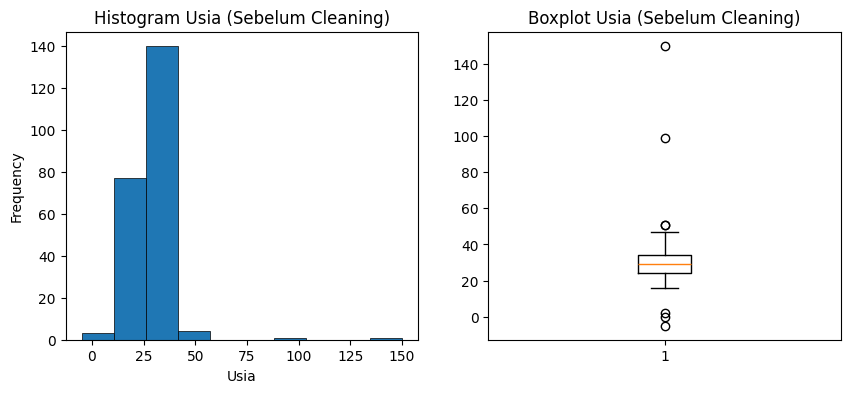

Outlier Usia (<= 0 atau >= 120):
     id_transaksi   usia
65      TRX-0066  150.0
134     TRX-0135   -5.0
139     TRX-0140    0.0

Outlier Jumlah Item (<= 0 atau > 20):
     id_transaksi  jumlah_item
78      TRX-0079         -2.0
100     TRX-0101         45.0
194     TRX-0195         60.0
207     TRX-0208          0.0

Outlier Total Harga (<= 0 atau > 1.000.000):
     id_transaksi  total_harga
18      TRX-0019     -35000.0
92      TRX-0093    9800000.0
139     TRX-0140    1250000.0
179     TRX-0180    4500000.0

Outlier Durasi Layanan (<= 0 atau > 60 menit):
     id_transaksi  durasi_layanan_menit
105     TRX-0106                 180.0
198     TRX-0199                  -3.0
208     TRX-0209                 240.0
229     TRX-0230                  95.0

Outlier Rating (< 1 atau > 5):
     id_transaksi  rating_kepuasan
62      TRX-0063              7.0
73      TRX-0074             -1.0
168     TRX-0169              0.0
204     TRX-0205              6.0
211     TRX-0212             10.0


In [ ]:
# === SEL 5: DETEKSI OUTLIER & VISUALISASI HISTOGRAM / BOXPLOT ===
# Visualisasi sebelum penanganan outlier (sesuai Sel 29 & 30 referensi)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df_trx['usia'].dropna(), edgecolor='black', linewidth=0.5)
axes[0].set_title('Histogram Usia (Sebelum Cleaning)')
axes[0].set_xlabel('Usia')
axes[0].set_ylabel('Frequency')

axes[1].boxplot(df_trx['usia'].dropna())
axes[1].set_title('Boxplot Usia (Sebelum Cleaning)')
plt.show()

# Cek nilai tidak logis / outlier pada kolom numerik
print("Outlier Usia (<= 0 atau >= 120):\n", df_trx[(df_trx['usia'] <= 0) | (df_trx['usia'] >= 120)][['id_transaksi', 'usia']])
print("\nOutlier Jumlah Item (<= 0 atau > 20):\n", df_trx[(df_trx['jumlah_item'] <= 0) | (df_trx['jumlah_item'] > 20)][['id_transaksi', 'jumlah_item']])
print("\nOutlier Total Harga (<= 0 atau > 1.000.000):\n", df_trx[(df_trx['total_harga'] <= 0) | (df_trx['total_harga'] > 1000000)][['id_transaksi', 'total_harga']])
print("\nOutlier Durasi Layanan (<= 0 atau > 60 menit):\n", df_trx[(df_trx['durasi_layanan_menit'] <= 0) | (df_trx['durasi_layanan_menit'] > 60)][['id_transaksi', 'durasi_layanan_menit']])
print("\nOutlier Rating (< 1 atau > 5):\n", df_trx[(df_trx['rating_kepuasan'] < 1) | (df_trx['rating_kepuasan'] > 5)][['id_transaksi', 'rating_kepuasan']])

# Ubah nilai tidak logis menjadi np.nan agar dapat diimputasi dengan statistik deskriptif
df_trx.loc[(df_trx['usia'] <= 0) | (df_trx['usia'] >= 120), 'usia'] = np.nan
df_trx.loc[(df_trx['jumlah_item'] <= 0) | (df_trx['jumlah_item'] > 20), 'jumlah_item'] = np.nan
df_trx.loc[(df_trx['total_harga'] <= 0) | (df_trx['total_harga'] > 1000000), 'total_harga'] = np.nan
df_trx.loc[(df_trx['durasi_layanan_menit'] <= 0) | (df_trx['durasi_layanan_menit'] > 60), 'durasi_layanan_menit'] = np.nan
df_trx.loc[(df_trx['rating_kepuasan'] < 1) | (df_trx['rating_kepuasan'] > 5), 'rating_kepuasan'] = np.nan

**1.5 Deteksi & Penanganan Missing Value**

=== JUMLAH MISSING VALUE PER KOLOM ===
id_transaksi             0
id_pelanggan             8
tanggal_transaksi        6
outlet                   9
jenis_kelamin           10
usia                    17
kategori_menu            8
jumlah_item             14
total_harga             16
metode_pembayaran        9
durasi_layanan_menit    17
rating_kepuasan         20
dtype: int64

=== CONTOH BARIS DENGAN MISSING VALUE ===


,id_transaksi,id_pelanggan,tanggal_transaksi,outlet,jenis_kelamin,usia,kategori_menu,jumlah_item,total_harga,metode_pembayaran,durasi_layanan_menit,rating_kepuasan
0,TRX-0001,CUST-092,2026-01-01,SURABAYA PUSAT,PEREMPUAN,33.0,CAMILAN,3.0,NaN,QRIS,14.6,4.0
1,TRX-0002,CUST-078,2026-01-01,SURABAYA PUSAT,PEREMPUAN,18.0,MAKANAN BERAT,2.0,63000.0,QRIS,8.4,NaN
5,TRX-0006,CUST-003,2026-01-02,NaN,LAKI-LAKI,25.0,KOPI,1.0,17000.0,E-WALLET,7.6,5.0
8,TRX-0009,CUST-093,2026-01-03,SURABAYA TIMUR,LAKI-LAKI,29.0,CAMILAN,1.0,25000.0,NaN,8.6,4.0
10,TRX-0011,CUST-103,2026-01-04,SURABAYA PUSAT,LAKI-LAKI,26.0,KOPI,NaN,65000.0,KARTU DEBIT,9.3,3.0


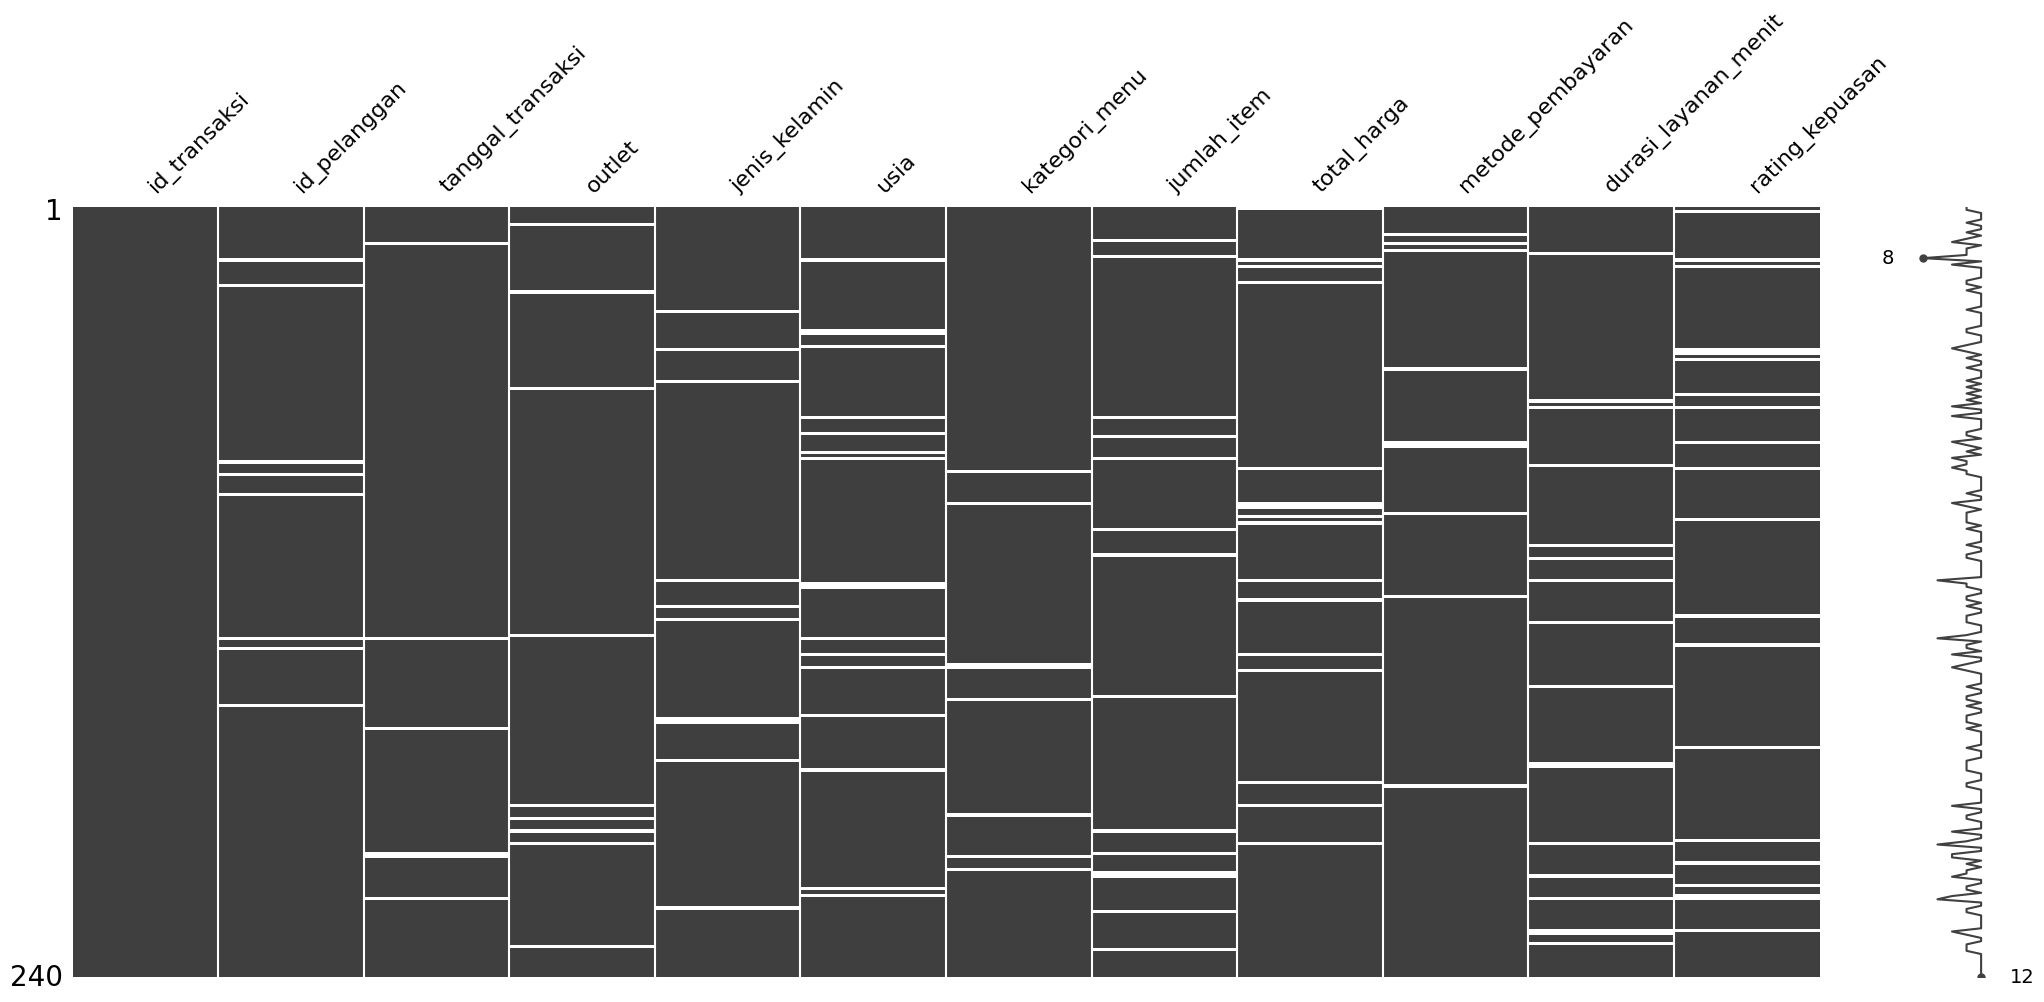

Jika dropna() semua baris, tersisa: 135 baris

Missing value setelah imputasi:
 id_transaksi            0
id_pelanggan            0
tanggal_transaksi       0
outlet                  0
jenis_kelamin           0
usia                    0
kategori_menu           0
jumlah_item             0
total_harga             0
metode_pembayaran       0
durasi_layanan_menit    0
rating_kepuasan         0
dtype: int64


In [ ]:
# === SEL 6: DETEKSI & PENANGANAN MISSING VALUE ===
# 1. Cek jumlah missing value per kolom & tampilkan baris kosong
print("=== JUMLAH MISSING VALUE PER KOLOM ===")
print(df_trx.isnull().sum())

print("\n=== CONTOH BARIS DENGAN MISSING VALUE ===")
display(df_trx[df_trx.isnull().any(axis=1)].head())

# 2. Visualisasi sebaran missing value dengan missingno
msno.matrix(df_trx)
plt.show()

# 3. Demonstrasi metode di referensi: dropna() & fillna(0) (pada salinan uji coba)
df_drop_row = df_trx.dropna()
df_fill_zero = df_trx.fillna(0)
print(f"Jika dropna() semua baris, tersisa: {len(df_drop_row)} baris")

# 4. Penanganan utama dataset Kopi Nusantara:
# - Hapus baris jika ID pelanggan atau tanggal transaksi kosong (tidak bisa dilacak)
df_trx = df_trx.dropna(subset=['id_pelanggan', 'tanggal_transaksi']).reset_index(drop=True)

# - Imputasi kolom numerik dengan Median / Mean (sesuai Sel 26 referensi)
df_trx['usia'] = df_trx['usia'].fillna(df_trx['usia'].median()).round(0)
df_trx['jumlah_item'] = df_trx['jumlah_item'].fillna(df_trx['jumlah_item'].median())
df_trx['total_harga'] = df_trx['total_harga'].fillna(df_trx['total_harga'].median())
df_trx['durasi_layanan_menit'] = df_trx['durasi_layanan_menit'].fillna(df_trx['durasi_layanan_menit'].mean()).round(2)
df_trx['rating_kepuasan'] = df_trx['rating_kepuasan'].fillna(df_trx['rating_kepuasan'].median())

# - Imputasi kolom kategorik dengan Modus (nilai paling sering muncul)
for col in ['outlet', 'jenis_kelamin', 'kategori_menu', 'metode_pembayaran']:
    df_trx[col] = df_trx[col].fillna(df_trx[col].mode()[0])

print("\nMissing value setelah imputasi:\n", df_trx.isnull().sum())

### **Tahap 2: Konversi Satuan & Data Integration**

In [ ]:
# === SEL 7: KONVERSI SATUAN & INTEGRASI DATASET ===
# 1. Integrasi vertikal: Gabungkan transaksi_januari & transaksi_februari
df_jan_feb = pd.concat([df_jan, df_feb], ignore_index=True)
print("Hasil gabung Januari + Februari:", df_jan_feb.shape)

# 2. Penyeragaman satuan waktu: Konversi pelayanan_detik.csv ke MENIT (/ 60)
kolom_waktu = ['waktu_antri', 'waktu_penyajian', 'waktu_pembayaran', 'total_waktu_layanan']
for c in kolom_waktu:
    df_detik.loc[(df_detik[c] <= 0) | (df_detik[c] > 3600), c] = np.nan
    df_menit.loc[(df_menit[c] <= 0) | (df_menit[c] > 60), c] = np.nan
    # Konversi satuan detik -> menit (dibulatkan 2 desimal)
    df_detik[c] = (df_detik[c] / 60).round(2)

# Lengkapi missing value pada pelayanan_menit menggunakan data pelayanan_detik yang sudah dikonversi
df_layanan = df_menit.set_index('id_transaksi').combine_first(
    df_detik.set_index('id_transaksi')
).reset_index()

# Bersihkan kategori pada df_layanan & df_pel sebelum merge
df_layanan['jenis_pesanan'] = df_layanan['jenis_pesanan'].astype(str).str.strip().str.upper().replace({
    'TAKE AWAY': 'TAKEAWAY', 'DINE IN': 'DINE-IN', 'ONLINE': 'DELIVERY', 'NAN': np.nan
})
df_layanan['status_layanan'] = df_layanan['status_layanan'].astype(str).str.strip().str.upper().replace({
    'CEP.': 'CEPAT', 'NOR.': 'NORMAL', 'LAM.': 'LAMBAT', 'NAN': np.nan
})
df_pel['status_member'] = df_pel['status_member'].astype(str).str.strip().str.upper().replace({'NAN': np.nan})
df_pel['kota'] = df_pel['kota'].astype(str).str.strip().str.upper().replace({
    'SBY': 'SURABAYA', 'SURABYA': 'SURABAYA', 'MLG': 'MALANG', 'NAN': np.nan
})

# 3. Integrasi horizontal (pd.merge): Gabungkan dataset_awal + data_pelanggan + data_layanan
df_integrated = pd.merge(
    df_trx,
    df_pel[['id_pelanggan', 'kota', 'status_member', 'frekuensi_kunjungan_bulan']],
    on='id_pelanggan',
    how='left'
)

df_integrated = pd.merge(
    df_integrated,
    df_layanan[['id_transaksi', 'jenis_pesanan', 'total_waktu_layanan', 'status_layanan']],
    on='id_transaksi',
    how='left'
)

# Isi nilai kosong hasil left-join profil pelanggan
df_integrated['kota'] = df_integrated['kota'].fillna('SURABAYA')
df_integrated['status_member'] = df_integrated['status_member'].fillna('REGULER')
df_integrated['frekuensi_kunjungan_bulan'] = df_integrated['frekuensi_kunjungan_bulan'].fillna(
    df_integrated['frekuensi_kunjungan_bulan'].median()
)

print("Ukuran dataset terintegrasi:", df_integrated.shape)
df_integrated.head()

Hasil gabung Januari + Februari: (240, 12)
Ukuran dataset terintegrasi: (227, 18)


,id_transaksi,id_pelanggan,tanggal_transaksi,outlet,jenis_kelamin,usia,kategori_menu,jumlah_item,total_harga,metode_pembayaran,durasi_layanan_menit,rating_kepuasan,kota,status_member,frekuensi_kunjungan_bulan,jenis_pesanan,total_waktu_layanan,status_layanan
0,TRX-0001,CUST-092,2026-01-01,SURABAYA PUSAT,PEREMPUAN,33.0,CAMILAN,3.0,38500.0,QRIS,14.6,4.0,SURABAYA,REGULER,2.0,DINE-IN,4.08,CEPAT
1,TRX-0002,CUST-078,2026-01-01,SURABAYA PUSAT,PEREMPUAN,18.0,MAKANAN BERAT,2.0,63000.0,QRIS,8.4,4.0,SIDOARJO,REGULER,7.0,NaN,NaN,NaN
2,TRX-0003,CUST-050,2026-01-01,SURABAYA BARAT,PEREMPUAN,33.0,CAMILAN,1.0,14000.0,QRIS,8.3,4.0,SURABAYA,REGULER,7.0,NaN,NaN,NaN
3,TRX-0004,CUST-019,2026-01-02,SURABAYA BARAT,PEREMPUAN,36.0,KOPI,2.0,51000.0,E-WALLET,13.4,4.0,SURABAYA,PLATINUM,5.0,DINE-IN,6.82,NORMAL
4,TRX-0005,CUST-079,2026-01-02,SURABAYA PUSAT,LAKI-LAKI,18.0,KOPI,2.0,47000.0,E-WALLET,6.5,5.0,SURABAYA,SILVER,7.0,NaN,NaN,NaN


### **Tahap 3: Data Transformation**

**3.1 Feature Scaling (Manual + Sklearn: Decimal, Min-Max, Z-Score, & Robust)**

In [ ]:
# === SEL 8: FEATURE SCALING (RUMUS MANUAL & SKLEARN) ===
df_trans = df_integrated.copy()

# 1. Decimal Scaling (Sel 1 referensi)
j = len(str(int(df_trans['total_harga'].abs().max())))
df_trans['harga_decimal'] = df_trans['total_harga'] / (10 ** j)

# 2. Min-Max Scaling: Rumus Manual + Round(3) & MinMaxScaler (Sel 2 & 3 referensi)
df_trans['harga_minmax_manual'] = (
    (df_trans['total_harga'] - df_trans['total_harga'].min()) /
    (df_trans['total_harga'].max() - df_trans['total_harga'].min())
).round(3)
df_trans['harga_minmax_sklearn'] = MinMaxScaler().fit_transform(df_trans[['total_harga']]).round(3)

# 3. Standardization (Z-Score): Rumus Manual + Round(3) & StandardScaler (Sel 4 & 5 referensi)
df_trans['harga_zscore_manual'] = (
    (df_trans['total_harga'] - df_trans['total_harga'].mean()) /
    df_trans['total_harga'].std()
).round(3)
df_trans['harga_zscore_sklearn'] = StandardScaler().fit_transform(df_trans[['total_harga']]).round(3)

# 4. Robust Scaling (IQR): Rumus Manual & RobustScaler (Sel 6 & 7 referensi)
q1 = df_trans['total_harga'].quantile(0.25)
q3 = df_trans['total_harga'].quantile(0.75)
iqr = q3 - q1
df_trans['harga_robust_manual'] = ((df_trans['total_harga'] - df_trans['total_harga'].median()) / iqr).round(3)
df_trans['harga_robust_sklearn'] = RobustScaler().fit_transform(df_trans[['total_harga']]).round(3)

display(df_trans[['total_harga', 'harga_decimal', 'harga_minmax_sklearn', 'harga_zscore_sklearn', 'harga_robust_sklearn']].head())

,total_harga,harga_decimal,harga_minmax_sklearn,harga_zscore_sklearn,harga_robust_sklearn
0,38500.0,0.0385,0.133,-0.309,0.000
1,63000.0,0.0630,0.247,0.387,0.778
2,14000.0,0.0140,0.019,-1.005,-0.778
3,51000.0,0.0510,0.191,0.046,0.397
4,47000.0,0.0470,0.172,-0.067,0.270


**3.2 Encoding Data Kategorikal & Diskritisasi (Binning)**

In [ ]:
# === SEL 9: LABEL ENCODING & DISKRITISASI (BINNING) ===
# 1. Label Encoding untuk variabel kategorik / ordinal (Sel 9 & 10 referensi)
le_outlet = LabelEncoder()
df_trans['outlet_encoded'] = le_outlet.fit_transform(df_trans['outlet'])

le_kategori = LabelEncoder()
df_trans['kategori_encoded'] = le_kategori.fit_transform(df_trans['kategori_menu'])

# Mapping ordinal eksplisit untuk status_member (Reguler < Silver < Gold < Platinum)
mapping_member = {'REGULER': 0, 'SILVER': 1, 'GOLD': 2, 'PLATINUM': 3}
df_trans['status_member_encoded'] = df_trans['status_member'].map(mapping_member)

# 2. Diskritisasi Equal-Width dengan pd.cut (Sel 12 referensi)
df_trans['kelompok_usia_cut'] = pd.cut(
    df_trans['usia'], bins=3, labels=['Muda', 'Dewasa', 'Senior']
)

# 3. Diskritisasi Equal-Frequency dengan pd.qcut (Sel 13 referensi)
df_trans['tingkat_belanja_qcut'] = pd.qcut(
    df_trans['total_harga'], q=3, labels=['Rendah', 'Sedang', 'Tinggi']
)

display(df_trans[['outlet', 'outlet_encoded', 'status_member', 'status_member_encoded', 'usia', 'kelompok_usia_cut', 'total_harga', 'tingkat_belanja_qcut']].head())

,outlet,outlet_encoded,status_member,status_member_encoded,usia,kelompok_usia_cut,total_harga,tingkat_belanja_qcut
0,SURABAYA PUSAT,1,REGULER,0,33.0,Muda,38500.0,Sedang
1,SURABAYA PUSAT,1,REGULER,0,18.0,Muda,63000.0,Tinggi
2,SURABAYA BARAT,0,REGULER,0,33.0,Muda,14000.0,Rendah
3,SURABAYA BARAT,0,PLATINUM,3,36.0,Dewasa,51000.0,Tinggi
4,SURABAYA PUSAT,1,SILVER,1,18.0,Muda,47000.0,Sedang


**3.3 Feature Engineering, Agregasi Data, & Data Smoothing**

In [ ]:
# === SEL 10: FEATURE ENGINEERING, AGREGASI, & DATA SMOOTHING ===
# 1. Feature Engineering (membuat fitur turunan baru, analogi BMI di Sel 18 referensi)
df_trans['rata_harga_per_item'] = (df_trans['total_harga'] / df_trans['jumlah_item']).round(2)

# 2. Agregasi Data per Kelompok (Sel 16 & 17 referensi)
data_num = df_trans[['outlet', 'jumlah_item', 'total_harga', 'durasi_layanan_menit', 'rating_kepuasan']]
data_agg = data_num.groupby('outlet').mean().round(2)
print("=== AGREGASI RATA-RATA PER OUTLET ===")
display(data_agg)

# 3. Data Smoothing pada rekap transaksi harian yang telah dibersihkan (Sel 20 referensi)
df_harian['tanggal'] = pd.to_datetime(df_harian['tanggal'], format='mixed', dayfirst=True, errors='coerce')
df_harian = df_harian.dropna(subset=['tanggal']).sort_values('tanggal').reset_index(drop=True)
df_harian.loc[(df_harian['total_pendapatan'] <= 0) | (df_harian['total_pendapatan'] > 20000000), 'total_pendapatan'] = np.nan
df_harian['total_pendapatan'] = df_harian['total_pendapatan'].fillna(df_harian['total_pendapatan'].median())

# Moving Average (window = 3)
df_harian['pendapatan_MA3'] = df_harian['total_pendapatan'].rolling(window=3).mean().round(2)

# Exponential Smoothing (alpha = 0.3)
df_harian['pendapatan_ES'] = df_harian['total_pendapatan'].ewm(alpha=0.3).mean().round(2)

print("=== HASIL DATA SMOOTHING PENDAPATAN HARIAN ===")
display(df_harian[['tanggal', 'outlet', 'total_pendapatan', 'pendapatan_MA3', 'pendapatan_ES']].head(8))

=== AGREGASI RATA-RATA PER OUTLET ===


,jumlah_item,total_harga,durasi_layanan_menit,rating_kepuasan
outlet,,,,
SURABAYA BARAT,2.18,50940.00,8.94,4.08
SURABAYA PUSAT,2.13,49013.27,9.15,4.19
SURABAYA TIMUR,2.22,48781.25,9.07,4.20


=== HASIL DATA SMOOTHING PENDAPATAN HARIAN ===


,tanggal,outlet,total_pendapatan,pendapatan_MA3,pendapatan_ES
0,2026-01-01,surabaya pusat,2583300.0,NaN,2583300.00
1,2026-01-01,Surabaya Timur,1734600.0,NaN,2084064.71
2,2026-01-01,Surabaya Barat,1996500.0,2104800.00,2044080.82
3,2026-01-02,Surabaya Pusat,2559600.0,2096900.00,2247602.01
4,2026-01-02,Surabaya Timur,2400000.0,2318700.00,2302557.83
5,2026-01-02,Surabaya Barat,1471100.0,2143566.67,2019861.55
6,2026-01-03,Surabaya Pusat,3941200.0,2604100.00,2647992.36
7,2026-01-03,Surabaya Timur,2112000.0,2508100.00,2477357.91


### **Tahap 4: Data Reduction & Simpan Hasil Akhir**

In [ ]:
# === SEL 11: DATA REDUCTION & EKSPOR DATASET SIAP ANALISIS ===
# Pilih fitur relevan dan buang kolom ID unik / kolom yang terlalu banyak missing dari join parsial
kolom_dibuang = ['id_transaksi', 'id_pelanggan', 'jenis_pesanan', 'total_waktu_layanan', 'status_layanan']
df_final = df_trans.drop(columns=kolom_dibuang)

print("Ukuran dataset sebelum reduction:", df_trans.shape)
print("Ukuran dataset final setelah reduction:", df_final.shape)
display(df_final.head())

# Simpan hasil akhir ke file CSV untuk diunggah ke repository GitHub
df_final.to_csv('dataset_kopi_nusantara_clean.csv', index=False)
df_harian.to_csv('transaksi_harian_clean.csv', index=False)
print("Seluruh tahapan Data Preprocessing selesai dan file hasil berhasil disimpan.")

Ukuran dataset sebelum reduction: (227, 31)
Ukuran dataset final setelah reduction: (227, 26)


,tanggal_transaksi,outlet,jenis_kelamin,usia,kategori_menu,jumlah_item,total_harga,metode_pembayaran,durasi_layanan_menit,rating_kepuasan,...,harga_zscore_manual,harga_zscore_sklearn,harga_robust_manual,harga_robust_sklearn,outlet_encoded,kategori_encoded,status_member_encoded,kelompok_usia_cut,tingkat_belanja_qcut,rata_harga_per_item
0,2026-01-01,SURABAYA PUSAT,PEREMPUAN,33.0,CAMILAN,3.0,38500.0,QRIS,14.6,4.0,...,-0.308,-0.309,0.000,0.000,1,0,0,Muda,Sedang,12833.33
1,2026-01-01,SURABAYA PUSAT,PEREMPUAN,18.0,MAKANAN BERAT,2.0,63000.0,QRIS,8.4,4.0,...,0.386,0.387,0.778,0.778,1,2,0,Muda,Tinggi,31500.00
2,2026-01-01,SURABAYA BARAT,PEREMPUAN,33.0,CAMILAN,1.0,14000.0,QRIS,8.3,4.0,...,-1.002,-1.005,-0.778,-0.778,0,0,0,Muda,Rendah,14000.00
3,2026-01-02,SURABAYA BARAT,PEREMPUAN,36.0,KOPI,2.0,51000.0,E-WALLET,13.4,4.0,...,0.046,0.046,0.397,0.397,0,1,3,Dewasa,Tinggi,25500.00
4,2026-01-02,SURABAYA PUSAT,LAKI-LAKI,18.0,KOPI,2.0,47000.0,E-WALLET,6.5,5.0,...,-0.067,-0.067,0.270,0.270,1,1,1,Muda,Sedang,23500.00


Seluruh tahapan Data Preprocessing selesai dan file hasil berhasil disimpan.
